# Inverse design of thin-film coatings (TiO2/SiO2, 8 layers, normal incidence)

Pipeline: TMM simulator -> dataset -> naive inverse network -> tandem network (physics in the loss) -> refinement with L-BFGS.

**Every new session: run cells 1, 2, 3, 8 first (and 9/14 are skipped by loading saved weights if you prefer).**

Run order for the first time: all cells top to bottom. GPU recommended: Runtime > Change runtime type > T4 GPU.

## 1. Mount Google Drive (run first, every session)

In [1]:
import os, shutil
from google.colab import drive

if not os.path.ismount("/content/drive"):
    # A leftover local /content/drive folder (from saving before mounting) blocks mounting.
    # It is not your real Drive, so it is safe to remove when Drive is NOT mounted.
    if os.path.exists("/content/drive"):
        shutil.rmtree("/content/drive")
    drive.mount("/content/drive")

assert os.path.ismount("/content/drive")
print("Drive mounted")

Mounted at /content/drive
Drive mounted


## 2. Settings

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ---- Drive guard: stops everything if Drive is not mounted (run cell 1 first) ----
assert os.path.ismount("/content/drive"), "Drive not mounted: run cell 1 first!"
SAVE_DIR = "/content/drive/MyDrive/thinfilm_data"
os.makedirs(SAVE_DIR, exist_ok=True)

# ---- settings ----
SEED      = 42
N_SAMPLES = 200_000          # use 5_000 for a quick test
N_LAYERS  = 8                # fixed number of layers (stage 1)
N_H, N_L  = 2.4, 1.46        # TiO2, SiO2
N_SUB, N_AIR = 1.52, 1.0     # glass substrate, air
LAM_MIN, LAM_MAX, N_LAM = 400, 800, 101
D_MIN, D_MAX = 20, 200       # nm
MIX = {"random": 0.40, "quarterwave": 0.25, "chirped": 0.20, "perturbed": 0.15}
REGENERATE = False           # True = regenerate and overwrite the saved data files

wavelengths = np.linspace(LAM_MIN, LAM_MAX, N_LAM)
layer_index = np.where(np.arange(N_LAYERS) % 2 == 0, N_H, N_L)   # H, L, H, L, ...
print("settings ready | save folder:", SAVE_DIR)

settings ready | save folder: /content/drive/MyDrive/thinfilm_data


## 3. TMM physics simulator + validation

In [3]:
def reflectance(d, n_list=None, lam=None):
    """TMM. d: (B, N) thicknesses in nm  ->  R: (B, N_LAM). Normal incidence."""
    n_list = layer_index if n_list is None else n_list
    lam = wavelengths if lam is None else lam
    d = np.atleast_2d(d)
    B = d.shape[0]
    m11 = np.ones((B, lam.size), dtype=complex)
    m12 = np.zeros((B, lam.size), dtype=complex)
    m21 = np.zeros((B, lam.size), dtype=complex)
    m22 = np.ones((B, lam.size), dtype=complex)
    for j in range(d.shape[1]):
        n = n_list[j]
        delta = 2 * np.pi * n * d[:, j:j+1] / lam[None, :]
        c, s = np.cos(delta), np.sin(delta)
        a11, a12, a21, a22 = c, -1j * s / n, -1j * n * s, c
        m11, m12, m21, m22 = (m11*a11 + m12*a21, m11*a12 + m12*a22,
                              m21*a11 + m22*a21, m21*a12 + m22*a22)
    Bv = m11 + m12 * N_SUB
    Cv = m21 + m22 * N_SUB
    r = (N_AIR * Bv - Cv) / (N_AIR * Bv + Cv)
    return (np.abs(r) ** 2).astype(np.float32)

def validate():
    lam0 = np.array([550.0])
    bare = reflectance(np.zeros((1, 0)), np.array([]), lam0)[0, 0]
    mgf2 = reflectance(np.array([[550/(4*1.38)]]), np.array([1.38]), lam0)[0, 0]
    qw   = reflectance(np.array([[550/(4*n) for n in layer_index]]), layer_index, lam0)[0, 0]
    print(f"bare glass {bare:.4f} (0.0426) | MgF2 {mgf2:.4f} (0.0126) | mirror {qw:.4f} (~0.952 if N=8)")
    assert abs(bare - 0.0426) < 1e-3 and abs(mgf2 - 0.0126) < 1e-3
    if N_LAYERS == 8: assert abs(qw - 0.952) < 5e-3
    assert np.allclose(reflectance(np.zeros((1, N_LAYERS))), 0.0426, atol=1e-3)
    print("TMM validation passed")

validate()

bare glass 0.0426 (0.0426) | MgF2 0.0126 (0.0126) | mirror 0.9518 (~0.952 if N=8)
TMM validation passed


## 4. Dataset generator

In [4]:
def sample_random(n, rng):
    return rng.uniform(D_MIN, D_MAX, (n, N_LAYERS))

def sample_quarterwave(n, rng):
    lam0 = rng.uniform(LAM_MIN, LAM_MAX, (n, 1))
    d = lam0 / (4 * layer_index[None, :])
    return d * (1 + rng.normal(0, 0.05, d.shape))

def sample_chirped(n, rng):
    a = rng.uniform(LAM_MIN, LAM_MAX, (n, 1))
    b = rng.uniform(LAM_MIN, LAM_MAX, (n, 1))
    lam_j = a + (b - a) * np.linspace(0, 1, N_LAYERS)[None, :]
    d = lam_j / (4 * layer_index[None, :])
    return d * (1 + rng.normal(0, 0.03, d.shape))

def sample_perturbed(n, rng):
    lam0 = rng.uniform(LAM_MIN, LAM_MAX, (n, 1))
    d = lam0 / (4 * layer_index[None, :])
    return d * (1 + rng.normal(0, 0.25, d.shape))

SAMPLERS = {"random": sample_random, "quarterwave": sample_quarterwave,
            "chirped": sample_chirped, "perturbed": sample_perturbed}

def generate(n_total, seed=SEED):
    rng = np.random.default_rng(seed)           # same seed -> same data every run
    ds, kinds = [], []
    for k, frac in MIX.items():
        n = int(round(n_total * frac))
        ds.append(np.clip(SAMPLERS[k](n, rng), D_MIN, D_MAX)); kinds += [k] * n
    d = np.vstack(ds).astype(np.float32)
    kinds = np.array(kinds)
    X = np.concatenate([reflectance(d[i:i+5000]) for i in range(0, len(d), 5000)])
    perm = rng.permutation(len(d))              # shuffle
    return X[perm], d[perm], kinds[perm]
print("generator ready")

generator ready


## 5. Generate and save the dataset (skips if files already exist)

In [5]:
need = ["train", "val", "test", "meta"]
exists = all(os.path.exists(f"{SAVE_DIR}/{f}.npz") for f in need)

if exists and not REGENERATE:
    print("Data files already exist -> skipping generation (set REGENERATE = True to redo).")
else:
    X, d, kinds = generate(N_SAMPLES)
    y = (d / D_MAX).astype(np.float32)           # thicknesses normalised to [0.1, 1]
    assert np.isfinite(X).all() and X.min() >= 0 and X.max() <= 1 + 1e-6
    n = len(X); i1, i2 = int(0.8*n), int(0.9*n)  # 80 / 10 / 10 split
    for name, sl in {"train": slice(0, i1), "val": slice(i1, i2), "test": slice(i2, n)}.items():
        np.savez_compressed(f"{SAVE_DIR}/{name}.npz", X=X[sl], y=y[sl], kinds=kinds[sl])
    np.savez(f"{SAVE_DIR}/meta.npz", wavelengths=wavelengths, layer_index=layer_index,
             D_MAX=D_MAX, N_SUB=N_SUB, N_AIR=N_AIR)
    print("generated and saved:", X.shape, y.shape, "->", SAVE_DIR)
print(sorted(os.listdir(SAVE_DIR)))

Data files already exist -> skipping generation (set REGENERATE = True to redo).
['dataset_sample.csv', 'dataset_sample.xlsx', 'fig_handmade_targets.png', 'fig_method_comparison.png', 'meta.npz', 'naive_inverse.pt', 'tandem_inverse.pt', 'test.npz', 'train.npz', 'val.npz']


## 6. Look at some samples

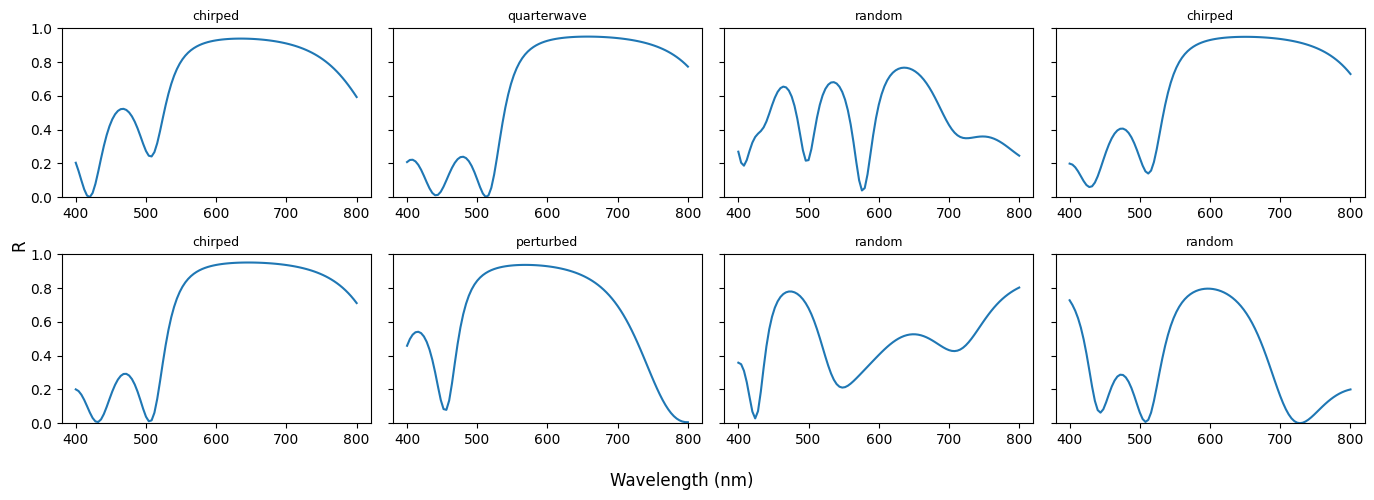

In [6]:
tr = np.load(f"{SAVE_DIR}/train.npz")
fig, axs = plt.subplots(2, 4, figsize=(14, 5), sharey=True)
for ax, i in zip(axs.ravel(), range(8)):
    ax.plot(wavelengths, tr["X"][i]); ax.set_title(str(tr["kinds"][i]), fontsize=9); ax.set_ylim(0, 1)
fig.supxlabel("Wavelength (nm)"); fig.supylabel("R"); plt.tight_layout(); plt.show()

## 7. Excel/CSV sample for the report

In [7]:
import pandas as pd
N_ROWS = 1000
tr = np.load(f"{SAVE_DIR}/train.npz")
X = tr["X"][:N_ROWS].astype(np.float64); y = tr["y"][:N_ROWS].astype(np.float64)
df = pd.concat([
    pd.DataFrame({"id": np.arange(N_ROWS), "type": tr["kinds"][:N_ROWS]}),
    pd.DataFrame(np.round(y * D_MAX, 1), columns=[f"d{j+1}_nm" for j in range(N_LAYERS)]),
    pd.DataFrame(np.round(X, 4), columns=[f"R_{int(w)}nm" for w in wavelengths]),
], axis=1)
df.to_csv(f"{SAVE_DIR}/dataset_sample.csv", index=False)
readme = pd.DataFrame({"Item": ["Purpose", "Rows", "Columns d1..d8", "Columns R_400nm..R_800nm",
    "Materials", "Substrate / medium", "Method", "Incidence", "Sampling types"], "Description": [
    "Training data for inverse design of thin-film coatings (spectrum -> layer thicknesses)",
    f"{N_ROWS} sample rows (full dataset: {N_SAMPLES})",
    "Layer thickness in nm. d1 touches air, d8 touches glass",
    "Reflectance (0 to 1) at 4 nm steps from 400 to 800 nm (101 points)",
    "Alternating TiO2 (n=2.4) and SiO2 (n=1.46), starting with TiO2",
    "Glass n=1.52, air n=1.0",
    "Transfer matrix method, lossless, constant refractive index",
    "Normal incidence", "random, quarterwave, chirped, perturbed"]})
with pd.ExcelWriter(f"{SAVE_DIR}/dataset_sample.xlsx") as w:
    df.to_excel(w, sheet_name="data", index=False)
    readme.to_excel(w, sheet_name="README", index=False)
print("saved dataset_sample.csv and .xlsx", df.shape)

saved dataset_sample.csv and .xlsx (1000, 111)


## 8. Load data into PyTorch

In [8]:
import torch
tr, va, te = (np.load(f"{SAVE_DIR}/{s}.npz") for s in ["train", "val", "test"])
Xtr, ytr = torch.tensor(tr["X"]), torch.tensor(tr["y"])
Xva, yva = torch.tensor(va["X"]), torch.tensor(va["y"])
Xte, yte = torch.tensor(te["X"]), torch.tensor(te["y"])
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
print("train", tuple(Xtr.shape), tuple(ytr.shape), "| val", tuple(Xva.shape), "| test", tuple(Xte.shape))
print("y range:", ytr.min().item(), ytr.max().item())

device: cuda
train (160000, 101) (160000, 8) | val (20000, 101) | test (20000, 101)
y range: 0.10000000149011612 1.0


## 9. Naive inverse network (baseline): spectrum -> thicknesses

In [9]:
import time, torch, torch.nn as nn

torch.manual_seed(SEED)

class InverseNet(nn.Module):
    """spectrum (101 numbers) -> thicknesses (8 numbers, scaled 0..1)"""
    def __init__(self, n_in=N_LAM, n_out=N_LAYERS, hidden=(512, 512, 256)):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers += [nn.Linear(prev, n_out), nn.Sigmoid()]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

model = InverseNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)
loss_fn = nn.MSELoss()

Xtr_d, ytr_d = Xtr.to(device), ytr.to(device)
Xva_d, yva_d = Xva.to(device), yva.to(device)

EPOCHS, BATCH, PATIENCE = 40, 512, 8
history = {"train": [], "val": []}
best_val, best_state, bad_epochs = float("inf"), None, 0

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    perm = torch.randperm(len(Xtr_d), device=device)
    total = 0.0
    for i in range(0, len(perm), BATCH):
        idx = perm[i:i + BATCH]
        opt.zero_grad()
        loss = loss_fn(model(Xtr_d[idx]), ytr_d[idx])
        loss.backward()
        opt.step()
        total += loss.detach() * len(idx)
    tr_loss = (total / len(perm)).item()

    model.eval()
    with torch.no_grad():
        va_loss = loss_fn(model(Xva_d), yva_d).item()
    sched.step(va_loss)
    history["train"].append(tr_loss); history["val"].append(va_loss)

    if va_loss < best_val:
        best_val, bad_epochs = va_loss, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        bad_epochs += 1

    if epoch == 1 or epoch % 5 == 0:
        print(f"epoch {epoch:3d} | train {tr_loss:.5f} | val {va_loss:.5f} | {time.time()-t0:.0f}s")
    if bad_epochs >= PATIENCE:
        print(f"early stop at epoch {epoch} (val loss stopped improving)")
        break

model.load_state_dict(best_state)                      # go back to the best epoch
torch.save(best_state, f"{SAVE_DIR}/naive_inverse.pt")
print(f"done in {time.time()-t0:.0f}s | best val loss {best_val:.5f} | saved naive_inverse.pt")

def predict(X_np):
    """numpy spectra (B,101) -> numpy thicknesses scaled 0..1 (B,8)"""
    model.eval()
    with torch.no_grad():
        out = model(torch.tensor(X_np, dtype=torch.float32).to(device))
    return out.cpu().numpy()

epoch   1 | train 0.02795 | val 0.02622 | 1s
epoch   5 | train 0.02299 | val 0.02306 | 3s
epoch  10 | train 0.02126 | val 0.02173 | 6s
epoch  15 | train 0.02005 | val 0.02115 | 9s
epoch  20 | train 0.01905 | val 0.02081 | 12s
epoch  25 | train 0.01818 | val 0.02075 | 15s
epoch  30 | train 0.01736 | val 0.02102 | 18s
epoch  35 | train 0.01583 | val 0.02059 | 21s
epoch  40 | train 0.01488 | val 0.02053 | 24s
done in 24s | best val loss 0.02048 | saved naive_inverse.pt


## 10. Naive network: loss curves

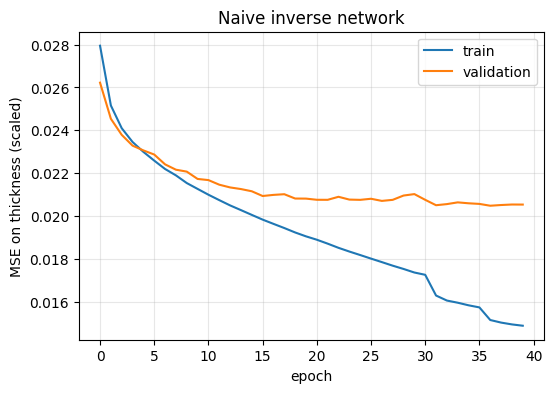

In [10]:
plt.figure(figsize=(6, 4))
plt.plot(history["train"], label="train"); plt.plot(history["val"], label="validation")
plt.xlabel("epoch"); plt.ylabel("MSE on thickness (scaled)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Naive inverse network"); plt.show()

## 11. Naive network: evaluate with the real physics

                                  thickness MAE (nm)   spectral MAE
random design                                      -         0.3294
always the average design                       30.8         0.3801
NAIVE NETWORK                                   16.8         0.1173

test targets matched within 0.02 mean error:  34.2 %
test targets matched within 0.05 mean error:  49.4 %
median spectral error: 0.0533   90th percentile: 0.2979

spectral MAE by sample type:
  chirped      0.0160
  perturbed    0.0853
  quarterwave  0.0156
  random       0.2400


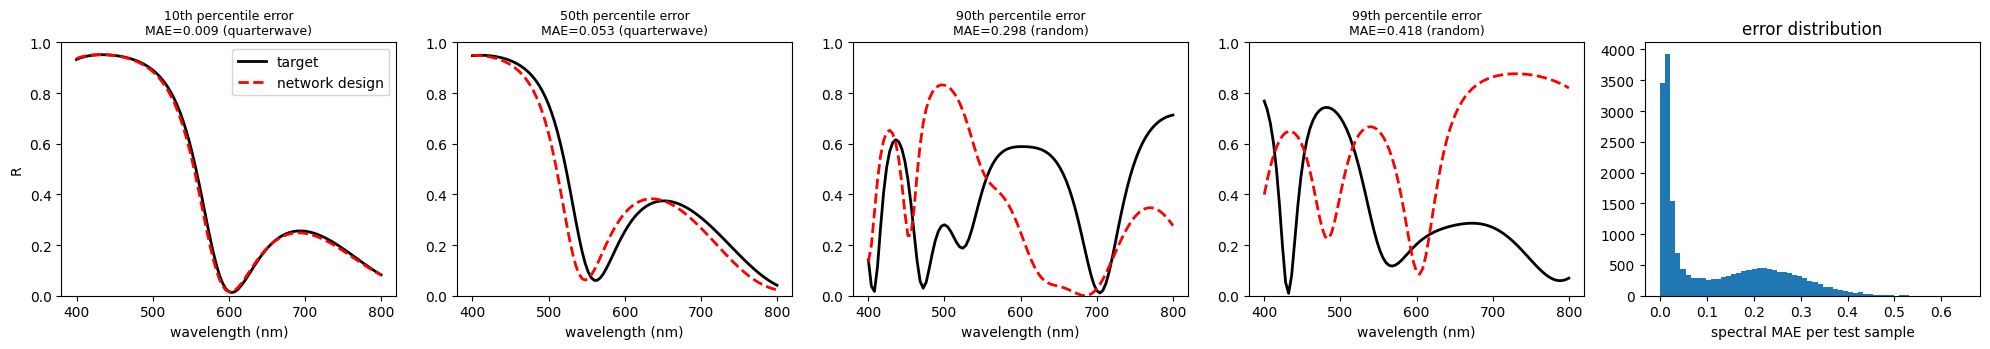

In [11]:
# ---------- evaluation on the TEST set: judge the DESIGN by its spectrum, not by its thicknesses ----------
R_target = te["X"]                     # what we asked for
true_nm  = te["y"] * D_MAX             # the stack that generated it (one of many valid answers!)
kinds_te = te["kinds"]

pred_nm = predict(R_target) * D_MAX    # network's design, in nm
R_pred  = reflectance(pred_nm)         # run the predicted design through the REAL physics (TMM)

thick_mae = np.abs(pred_nm - true_nm).mean()
spec_mae  = np.abs(R_pred - R_target).mean(axis=1)       # per-sample spectral error

# two dumb baselines to compare against
rng_e = np.random.default_rng(0)
R_rand = reflectance(rng_e.uniform(D_MIN, D_MAX, pred_nm.shape))
mean_nm = tr["y"].mean(axis=0) * D_MAX
R_mean = reflectance(np.tile(mean_nm, (len(R_target), 1)))

print(f"{'':32s}{'thickness MAE (nm)':>20s}{'spectral MAE':>15s}")
print(f"{'random design':32s}{'-':>20s}{np.abs(R_rand - R_target).mean():>15.4f}")
print(f"{'always the average design':32s}{np.abs(mean_nm - true_nm).mean():>20.1f}{np.abs(R_mean - R_target).mean():>15.4f}")
print(f"{'NAIVE NETWORK':32s}{thick_mae:>20.1f}{spec_mae.mean():>15.4f}")
print()
print(f"test targets matched within 0.02 mean error: {(spec_mae < 0.02).mean()*100:5.1f} %")
print(f"test targets matched within 0.05 mean error: {(spec_mae < 0.05).mean()*100:5.1f} %")
print(f"median spectral error: {np.median(spec_mae):.4f}   90th percentile: {np.percentile(spec_mae, 90):.4f}")
print("\nspectral MAE by sample type:")
for k in np.unique(kinds_te):
    print(f"  {k:12s} {spec_mae[kinds_te == k].mean():.4f}")

# plots: four examples (good -> bad) and the error histogram
order = np.argsort(spec_mae)
picks = [order[int(q * (len(order) - 1))] for q in (0.10, 0.50, 0.90, 0.99)]
fig, axs = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, i, q in zip(axs[:4], picks, (10, 50, 90, 99)):
    ax.plot(wavelengths, R_target[i], "k", lw=2, label="target")
    ax.plot(wavelengths, R_pred[i], "r--", lw=2, label="network design")
    ax.set_title(f"{q}th percentile error\nMAE={spec_mae[i]:.3f} ({kinds_te[i]})", fontsize=9)
    ax.set_ylim(0, 1); ax.set_xlabel("wavelength (nm)")
axs[0].legend(); axs[0].set_ylabel("R")
axs[4].hist(spec_mae, bins=60); axs[4].set_xlabel("spectral MAE per test sample"); axs[4].set_title("error distribution")
plt.tight_layout(); plt.show()

## 12. Hand-made targets (mirror, anti-reflection, dip) with the naive network

Mirror 480-650 nm        MAE 0.309 | thicknesses (nm): [194, 80, 50, 69, 127, 131, 176, 85]
Broadband AR (R=0.02)    MAE 0.358 | thicknesses (nm): [11, 11, 82, 152, 91, 39, 52, 107]
Dip at 600 nm            MAE 0.141 | thicknesses (nm): [73, 86, 126, 80, 92, 104, 186, 111]


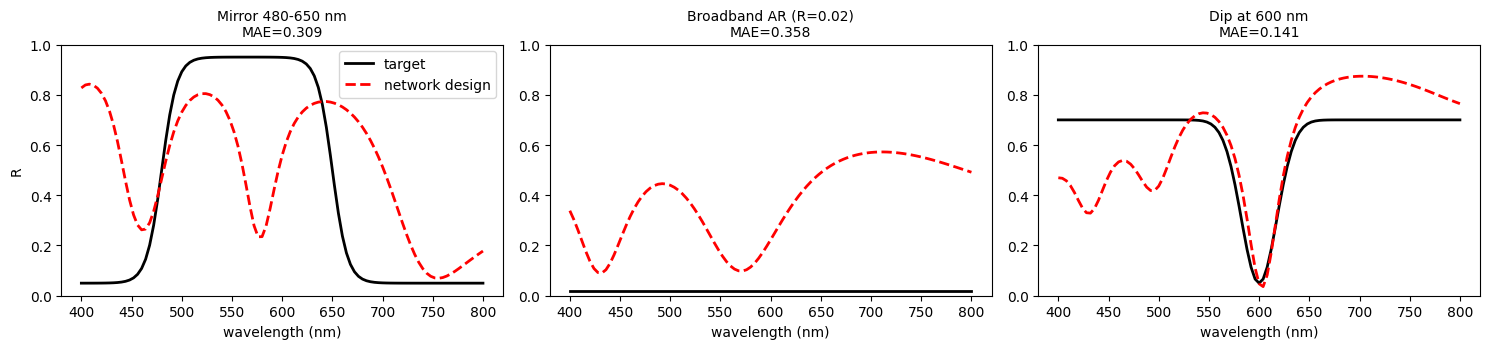

In [12]:
# ---------- hand-made targets (what a user would actually ask for) ----------
def box(lo, hi, high, low, edge=15):
    return low + (high - low) * 0.5 * (np.tanh((wavelengths - lo) / edge) - np.tanh((wavelengths - hi) / edge))

targets = {
    "Mirror 480-650 nm":     box(480, 650, 0.95, 0.05),
    "Broadband AR (R=0.02)": np.full(N_LAM, 0.02),
    "Dip at 600 nm":         0.7 - 0.65 * np.exp(-((wavelengths - 600) / 25) ** 2),
}
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (name, t) in zip(axs, targets.items()):
    nm = predict(t[None, :].astype(np.float32)) * D_MAX
    R = reflectance(nm)[0]
    ax.plot(wavelengths, t, "k", lw=2, label="target"); ax.plot(wavelengths, R, "r--", lw=2, label="network design")
    ax.set_title(f"{name}\nMAE={np.abs(R - t).mean():.3f}", fontsize=10); ax.set_ylim(0, 1); ax.set_xlabel("wavelength (nm)")
    print(f"{name:24s} MAE {np.abs(R - t).mean():.3f} | thicknesses (nm): {np.round(nm[0], 0).astype(int).tolist()}")
axs[0].legend(); axs[0].set_ylabel("R"); plt.tight_layout(); plt.show()

## 13. Differentiable TMM in PyTorch (with self-test)

In [13]:
# ---------- differentiable TMM in PyTorch (lets the network learn THROUGH the physics) ----------
N_LIST = [float(x) for x in layer_index]
LAM_T  = torch.tensor(wavelengths, dtype=torch.float32, device=device)

def reflectance_xp(d, n_list, lam, n_air, n_sub, xp):
    """Real-valued TMM. Works with numpy (xp=np) and torch (xp=torch). d:(B,N), lam:(L,) -> R:(B,L)"""
    base = d[:, :1] / lam[None, :]
    A = xp.ones_like(base); B = xp.zeros_like(base); C = xp.zeros_like(base); D = xp.ones_like(base)
    for j, n in enumerate(n_list):
        delta = 6.283185307179586 * n * d[:, j:j+1] / lam[None, :]
        c, s = xp.cos(delta), xp.sin(delta)
        a, b, cc, dd = c, -s / n, -n * s, c
        A, B, C, D = A*a - B*cc, A*b + B*dd, C*a + D*cc, -C*b + D*dd
    nr, ni = n_air*A - D*n_sub, n_air*B*n_sub - C
    dr, di = n_air*A + D*n_sub, n_air*B*n_sub + C
    return (nr*nr + ni*ni) / (dr*dr + di*di)

def reflectance_torch(d_nm):
    return reflectance_xp(d_nm, N_LIST, LAM_T, float(N_AIR), float(N_SUB), torch)

# self-test: torch physics must agree with the numpy physics we validated earlier
_d = np.random.default_rng(1).uniform(D_MIN, D_MAX, (5, N_LAYERS)).astype(np.float32)
_diff = np.abs(reflectance_torch(torch.tensor(_d, device=device)).cpu().numpy() - reflectance(_d)).max()
print("torch TMM vs numpy TMM, max difference:", _diff)
assert _diff < 1e-3, "torch TMM disagrees with numpy TMM"

torch TMM vs numpy TMM, max difference: 8.1956387e-07


## 14. Tandem network: loss on the spectrum, through the physics (warm-started from the naive network)

In [14]:
# ---------- TANDEM network: loss is on the SPECTRUM, computed by the physics ----------
torch.manual_seed(SEED)
tandem = InverseNet().to(device)                       # same architecture as the naive network
# WARM START: begin from the trained naive network (training from random weights gets stuck in a poor solution)
tandem.load_state_dict(torch.load(f"{SAVE_DIR}/naive_inverse.pt", map_location=device))
opt = torch.optim.Adam(tandem.parameters(), lr=3e-4)   # smaller learning rate for fine-tuning
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)

def to_nm(out):                                        # sigmoid output (0..1) -> thickness in [D_MIN, D_MAX] nm
    return D_MIN + (D_MAX - D_MIN) * out

EPOCHS, BATCH, PATIENCE = 30, 512, 8
history_t = {"train": [], "val": []}
best_val, best_state, bad_epochs = float("inf"), None, 0

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    tandem.train()
    perm = torch.randperm(len(Xtr_d), device=device)
    total = 0.0
    for i in range(0, len(perm), BATCH):
        idx = perm[i:i + BATCH]
        x = Xtr_d[idx]
        opt.zero_grad()
        loss = ((reflectance_torch(to_nm(tandem(x))) - x) ** 2).mean()   # spectrum vs target, through physics
        loss.backward()
        opt.step()
        total += loss.detach() * len(idx)
    tr_loss = (total / len(perm)).item()

    tandem.eval()
    with torch.no_grad():
        va_loss = ((reflectance_torch(to_nm(tandem(Xva_d))) - Xva_d) ** 2).mean().item()
    sched.step(va_loss)
    history_t["train"].append(tr_loss); history_t["val"].append(va_loss)

    if va_loss < best_val:
        best_val, bad_epochs = va_loss, 0
        best_state = {k: v.clone() for k, v in tandem.state_dict().items()}
    else:
        bad_epochs += 1
    if epoch == 1 or epoch % 5 == 0:
        print(f"epoch {epoch:3d} | train spectral MSE {tr_loss:.5f} | val {va_loss:.5f} | {time.time()-t0:.0f}s")
    if bad_epochs >= PATIENCE:
        print(f"early stop at epoch {epoch}")
        break

tandem.load_state_dict(best_state)
torch.save(best_state, f"{SAVE_DIR}/tandem_inverse.pt")
print(f"done in {time.time()-t0:.0f}s | best val spectral MSE {best_val:.5f} | saved tandem_inverse.pt")

def predict_tandem(X_np):
    """numpy spectra (B,101) -> numpy thicknesses in nm (B,8)"""
    tandem.eval()
    with torch.no_grad():
        out = tandem(torch.tensor(X_np, dtype=torch.float32).to(device))
    return to_nm(out).cpu().numpy()

epoch   1 | train spectral MSE 0.03139 | val 0.02661 | 3s
epoch   5 | train spectral MSE 0.01882 | val 0.01906 | 15s
epoch  10 | train spectral MSE 0.01455 | val 0.01523 | 30s
epoch  15 | train spectral MSE 0.01244 | val 0.01349 | 45s
epoch  20 | train spectral MSE 0.01115 | val 0.01262 | 61s
epoch  25 | train spectral MSE 0.01028 | val 0.01195 | 76s
epoch  30 | train spectral MSE 0.00964 | val 0.01159 | 91s
done in 92s | best val spectral MSE 0.01159 | saved tandem_inverse.pt


## 15. Naive vs tandem on the full test set

                  mean MAE   median    <0.02    <0.05
naive               0.1173   0.0533    34.2%    49.4%
tandem              0.0589   0.0246    45.9%    59.0%

by sample type (mean spectral MAE):
  chirped      naive 0.0160 | tandem 0.0118
  perturbed    naive 0.0853 | tandem 0.0365
  quarterwave  naive 0.0156 | tandem 0.0112
  random       naive 0.2400 | tandem 0.1192


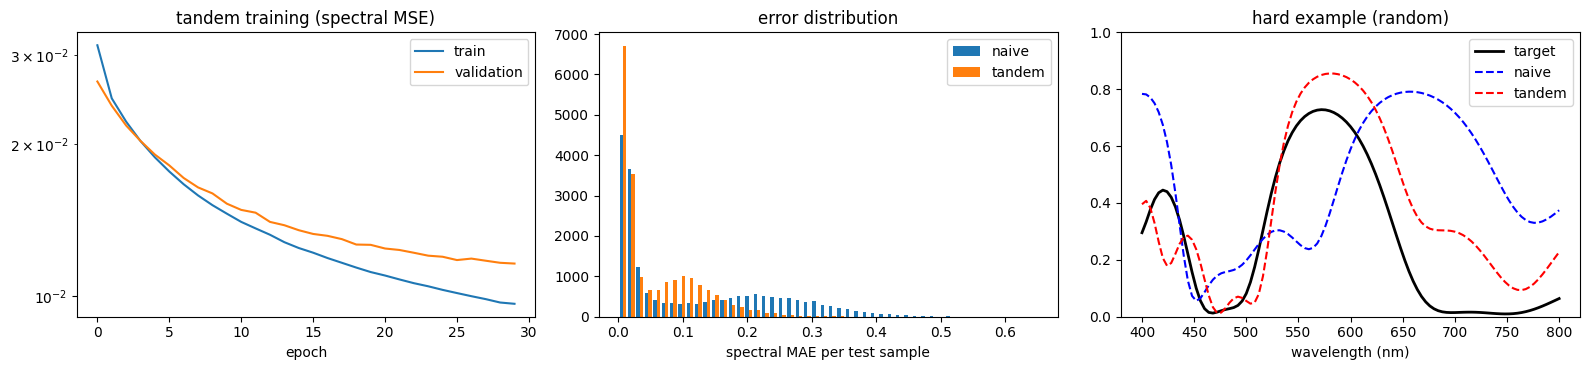

In [15]:
# ---------- naive vs tandem on the FULL test set ----------
R_target = te["X"]; kinds_te = te["kinds"]
pred_naive  = predict(R_target) * D_MAX
pred_tandem = predict_tandem(R_target)

def spec_error(pred_nm, target):                      # per-sample mean absolute spectral error, via the REAL TMM
    return np.abs(reflectance(pred_nm) - target).mean(axis=1)

err_naive, err_tandem = spec_error(pred_naive, R_target), spec_error(pred_tandem, R_target)
print(f"{'':16s}{'mean MAE':>10s}{'median':>9s}{'<0.02':>9s}{'<0.05':>9s}")
for name, e in [("naive", err_naive), ("tandem", err_tandem)]:
    print(f"{name:16s}{e.mean():>10.4f}{np.median(e):>9.4f}{(e<0.02).mean()*100:>8.1f}%{(e<0.05).mean()*100:>8.1f}%")
print("\nby sample type (mean spectral MAE):")
for k in np.unique(kinds_te):
    mk = kinds_te == k
    print(f"  {k:12s} naive {err_naive[mk].mean():.4f} | tandem {err_tandem[mk].mean():.4f}")

fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
axs[0].plot(history_t["train"], label="train"); axs[0].plot(history_t["val"], label="validation")
axs[0].set_yscale("log"); axs[0].set_title("tandem training (spectral MSE)"); axs[0].set_xlabel("epoch"); axs[0].legend()
axs[1].hist([err_naive, err_tandem], bins=50, label=["naive", "tandem"]); axs[1].set_xlabel("spectral MAE per test sample")
axs[1].set_title("error distribution"); axs[1].legend()
order = np.argsort(err_tandem); i = order[int(0.9 * (len(order) - 1))]       # a hard example (90th percentile)
axs[2].plot(wavelengths, R_target[i], "k", lw=2, label="target")
axs[2].plot(wavelengths, reflectance(pred_naive[i:i+1])[0], "b--", label="naive")
axs[2].plot(wavelengths, reflectance(pred_tandem[i:i+1])[0], "r--", label="tandem"); axs[2].legend()
axs[2].set_title(f"hard example ({kinds_te[i]})"); axs[2].set_ylim(0, 1); axs[2].set_xlabel("wavelength (nm)")
plt.tight_layout(); plt.show()

## 16. Refinement: network design as the starting point for L-BFGS, compared with random starts

In [ ]:
# ---------- refinement: use the network's design as the STARTING POINT of a classical optimiser ----------
from scipy.optimize import minimize

def loss_and_grad(d, X, n_list, lam, n_air, n_sub):
    """per-sample loss = mean_lambda (R-X)^2 and its analytic gradient wrt thicknesses (numpy, float64)."""
    d = np.asarray(d, np.float64); Bn, N = d.shape; L = lam.size
    nl = np.array(n_list, float)[None, :, None]
    k = 2*np.pi*nl/lam[None, None, :]
    delta = k * d[:, :, None]; c, s = np.cos(delta), np.sin(delta)
    mul = lambda P, Q: (P[0]*Q[0]-P[1]*Q[2], P[0]*Q[1]+P[1]*Q[3], P[2]*Q[0]+P[3]*Q[2], -P[2]*Q[1]+P[3]*Q[3])
    Ls  = [(c[:, j], -s[:, j]/nl[0, j], -nl[0, j]*s[:, j], c[:, j]) for j in range(N)]
    dLs = [(-s[:, j]*k[0, j], -c[:, j]*k[0, j]/nl[0, j], -nl[0, j]*c[:, j]*k[0, j], -s[:, j]*k[0, j]) for j in range(N)]
    one, zero = np.ones((Bn, L)), np.zeros((Bn, L)); I = (one, zero, zero, one)
    pre = [I]
    for j in range(N): pre.append(mul(pre[-1], Ls[j]))
    suf = [None]*N + [I]
    for j in range(N-1, -1, -1): suf[j] = mul(Ls[j], suf[j+1])
    A, B, C, D = pre[N]
    Bv = A + 1j*B*n_sub; Cv = D*n_sub + 1j*C
    Nn, Dn = n_air*Bv - Cv, n_air*Bv + Cv; r = Nn/Dn; R = np.abs(r)**2
    err = R - X; loss = (err**2).mean(axis=1); grad = np.zeros((Bn, N))
    for j in range(N):
        dA, dB, dC, dD = mul(mul(pre[j], dLs[j]), suf[j+1])
        dBv = dA + 1j*dB*n_sub; dCv = dD*n_sub + 1j*dC
        dN, dDn = n_air*dBv - dCv, n_air*dBv + dCv
        dr = (dN*Dn - Nn*dDn)/Dn**2; dR = 2*np.real(np.conj(r)*dr)
        grad[:, j] = (2*err*dR).mean(axis=1)
    return loss, grad, R

def refine(x0_nm, target, maxiter=200):
    def fun(d):
        l, g, _ = loss_and_grad(d[None, :], target[None, :], N_LIST, wavelengths, N_AIR, N_SUB)
        return l[0], g[0]
    res = minimize(fun, np.asarray(x0_nm, np.float64), jac=True, method="L-BFGS-B",
                   bounds=[(D_MIN, D_MAX)] * N_LAYERS, options={"maxiter": maxiter})
    return res.x, res.fun

N_REF = 300                                              # number of test targets used for the comparison
rng_r = np.random.default_rng(123)
sub = np.arange(N_REF)
out = {name: {"x": [], "t": []} for name in ["naive", "tandem", "naive + refine", "tandem + refine",
                                             "random start + refine", "best of 5 random + refine"]}
for i in sub:
    tgt = R_target[i].astype(np.float64)
    out["naive"]["x"].append(pred_naive[i]); out["tandem"]["x"].append(pred_tandem[i])
    for name, x0 in [("naive + refine", pred_naive[i]), ("tandem + refine", pred_tandem[i])]:
        t = time.perf_counter(); x, _ = refine(x0, tgt); out[name]["x"].append(x); out[name]["t"].append(time.perf_counter() - t)
    t = time.perf_counter(); x, _ = refine(rng_r.uniform(D_MIN, D_MAX, N_LAYERS), tgt)
    out["random start + refine"]["x"].append(x); out["random start + refine"]["t"].append(time.perf_counter() - t)
    t = time.perf_counter(); cands = [refine(rng_r.uniform(D_MIN, D_MAX, N_LAYERS), tgt) for _ in range(5)]
    out["best of 5 random + refine"]["x"].append(min(cands, key=lambda c: c[1])[0]); out["best of 5 random + refine"]["t"].append(time.perf_counter() - t)

summary = {}
print(f"{'method':28s}{'mean MAE':>10s}{'median':>9s}{'<0.02':>8s}{'<0.05':>8s}{'sec/target':>12s}")
for name, v in out.items():
    e = spec_error(np.array(v["x"]), R_target[sub]); summary[name] = e
    sec = f"{np.mean(v['t']):.2f}" if v["t"] else "~0.001"
    print(f"{name:28s}{e.mean():>10.4f}{np.median(e):>9.4f}{(e<0.02).mean()*100:>7.0f}%{(e<0.05).mean()*100:>7.0f}%{sec:>12s}")

# ---------- multi-start: refine from BOTH network designs (naive and tandem) and keep the better result ----------
best_x, t_total = [], 0.0
for i in sub:
    tgt = R_target[i].astype(np.float64)
    t = time.perf_counter()
    cands = [refine(pred_naive[i], tgt), refine(pred_tandem[i], tgt)]      # each returns (thicknesses, final loss)
    t_total += time.perf_counter() - t
    best_x.append(min(cands, key=lambda c: c[1])[0])
e = spec_error(np.array(best_x), R_target[sub]); summary["naive & tandem starts + refine"] = e
print(f"{'naive & tandem starts + refine':28s}{e.mean():>10.4f}{np.median(e):>9.4f}{(e<0.02).mean()*100:>7.0f}%{(e<0.05).mean()*100:>7.0f}%{t_total/len(sub):>12.2f}")

## 17. Final figures (saved to Drive)

In [ ]:
# ---------- final figures for the report ----------
names = list(summary.keys())
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(names, [summary[n].mean() for n in names], color=["#2a9d4a" if "&" in n else "#cc4444" if n.startswith("tandem") else "#8888cc" if n.startswith("naive") else "#999999" for n in names])
ax.set_xlabel(f"mean spectral MAE on {N_REF} test targets (lower is better)"); ax.invert_yaxis(); plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/fig_method_comparison.png", dpi=150); plt.show()

# hand-made targets: tandem network, then tandem + refinement
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (name, t) in zip(axs, targets.items()):
    t = t.astype(np.float64)
    nm = predict_tandem(t[None, :].astype(np.float32))[0]
    nm_ref, _ = refine(nm, t)
    R1, R2 = reflectance(nm[None, :])[0], reflectance(nm_ref[None, :])[0]
    ax.plot(wavelengths, t, "k", lw=2, label="target"); ax.plot(wavelengths, R1, "r--", label=f"tandem (MAE {np.abs(R1-t).mean():.3f})")
    ax.plot(wavelengths, R2, "g-", label=f"tandem + refine (MAE {np.abs(R2-t).mean():.3f})")
    ax.set_title(name); ax.set_ylim(0, 1); ax.set_xlabel("wavelength (nm)"); ax.legend(fontsize=8)
    print(f"{name:24s} refined thicknesses (nm): {np.round(nm_ref).astype(int).tolist()}")
axs[0].set_ylabel("R"); plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/fig_handmade_targets.png", dpi=150); plt.show()